# Figure 2

In [25]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_behavioral_data,
    load_choicehistorysvpartitions_contrasts,
    load_sv_partition_means,
    load_rtlme_switch_fixed_effects,
    DATASET_CURRENCY,
    LOSS_AVERSION,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [26]:
def _fmt_tick(v):
    try:
        return f"{float(v):g}"
    except (ValueError, TypeError):
        return str(v)


def format_pvalue(p):
    """APA-style p-value: p<.001, else p=.XXX (leading zero dropped)."""
    return ""
    # if p < 0.001:
    #     return "p<.001"
        
    # return f"p={p:.3f}".replace("0.", ".", 1)


def plot_gain_loss_heatmap(ax, hmap_data, dataset, cmap, vmin, vmax, cbar_label,
                           show_loss_aversion=True):
    """Gain (rows) x loss (columns) heatmap, optionally with the gain =
    lambda * loss loss-aversion diagonal. hmap_data: index=loss, columns=gain."""
    losses = hmap_data.index.values.astype(float)
    gains  = hmap_data.columns.values.astype(float)
    hmap_t = hmap_data.T  # rows=gain, columns=loss

    sns.heatmap(
        hmap_t, cmap=cmap, square=True, linewidths=1, linecolor="black",
        vmin=vmin, vmax=vmax, cbar=True, cbar_kws={"label": cbar_label},
        ax=ax, xticklabels=True, yticklabels=True,
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(rotation=90)
    ax.invert_yaxis()  # gain increases from bottom to top

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

    if show_loss_aversion:
        lambd = LOSS_AVERSION.get(dataset)
        if lambd is not None:
            n_rows, n_cols = len(gains), len(losses)
            loss_endpoints = np.array([losses.min(), losses.max()])
            gain_endpoints = lambd * loss_endpoints
            loss_coords = (
                0.5 + (loss_endpoints - losses.min())
                / (losses.max() - losses.min()) * (n_cols - 1)
            )
            gain_coords = (
                0.5 + (gain_endpoints - gains.min())
                / (gains.max() - gains.min()) * (n_rows - 1)
            )
            ax.plot(loss_coords, gain_coords, color="black", linestyle="--", linewidth=4)

    currency = DATASET_CURRENCY.get(dataset, "")
    ax.set_xlabel(f"Loss ({currency})")
    ax.set_ylabel(f"Gain ({currency})")
    ax.set_xticklabels([_fmt_tick(v) for v in losses])
    ax.set_yticklabels([_fmt_tick(v) for v in gains])


def plot_historyeffect_by_sv(ax, ds_contrasts, ds_sv_means, ylim):
    """Prev. Accept - Prev. Reject P(accept) per SV partition, p-value above each point."""
    x_pos = np.arange(len(ds_contrasts))
    means = ds_contrasts["historyeffect"].values
    los   = ds_contrasts["asymp.LCL"].values
    his   = ds_contrasts["asymp.UCL"].values

    ax.errorbar(x_pos, means, yerr=[means - los, his - means], fmt="o-", color="purple",
                markersize=16, capsize=6, elinewidth=2.5, linewidth=2.5, zorder=2)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)

    sv0_x = np.interp(0, np.round(ds_sv_means), x_pos)
    ax.axvline(sv0_x, color="black", linewidth=1, linestyle="--", zorder=1)

    for x, y_top, p in zip(x_pos, his, ds_contrasts["p.value"]):
        ax.annotate(format_pvalue(p), xy=(x, y_top), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=12)

    ax.set_xlim(-0.5, len(x_pos) - 0.5)
    ax.set_ylim(*ylim)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([f"{round(v):2d}" for v in ds_sv_means])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def p_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def plot_switch_bar(ax, switch_row, color="tan"):
    """Switch - repeat RT (ms) from the rtlme_switch Gamma GLMM, 95% CI, stars = p."""
    estimate = 1000 * switch_row["estimate"]
    lo, hi = 1000 * switch_row["conf.low"], 1000 * switch_row["conf.high"]
    ax.bar(0, estimate, yerr=[[estimate - lo], [hi - estimate]], width=0.6, color=color,
           error_kw={"elinewidth": 2.5, "capsize": 10}, zorder=3)
    ax.annotate(p_stars(switch_row["p.value"]), xy=(0, hi), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom",
                fontsize=18, fontweight="bold")
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)
    ax.set_xlim(-0.6, 0.6)
    ax.set_xticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)

### 2x3 figure: acceptance grids, choice-history effect by SV partition
Columns = datasets. Row 1: acceptance rate across gain x loss. Row 2: choice-history effect (Prev. Accept - Prev. Reject predicted P(accept)) by subjective-value partition, with per-partition p-values; next to each, the switch − repeat RT difference (ms, 95% CI, stars = p) from the `rtlme_switch` Gamma GLMM (`results/analysis_rtlme/1_rtlme_switch_fixed_effects.csv`).

In [31]:
behavior_data = load_behavioral_data()
choicehistoryeffect_contrasts = load_choicehistorysvpartitions_contrasts()
sv_partition_means = load_sv_partition_means()
switch_effects = (load_rtlme_switch_fixed_effects()
                  .query("term == 'switch'")
                  .set_index("dataset"))

ACCEPT_CMAP = "RdBu_r"
SV_PARTITIONS = [1, 2, 3, 4, 5]
HISTORYEFFECT_YLIM = (-0.01, 0.23)
SWITCH_YLIM = (0, 160)  # ms; shared across datasets
ROW_LABELS = ["A.", "B."]

accept_hmaps = {}
for ds in DATASETS:
    ds_data = behavior_data[behavior_data["dataset"] == ds]
    subj_cell_means = ds_data.groupby(["sub", "loss", "gain"])["accept"].mean().reset_index()
    accept_hmaps[ds] = subj_cell_means.groupby(["loss", "gain"])["accept"].mean().unstack()


def set_dataset_titles(row_axes):
    for ax, ds in zip(row_axes, DATASETS):
        ax.set_title(f"{DATASET_LABELS.get(ds, ds)}\n", fontweight="bold")


# --- Row 1: acceptance rate across gain x loss ---
def draw_acceptance_row(row_axes):
    for ax, ds in zip(row_axes, DATASETS):
        plot_gain_loss_heatmap(
            ax, accept_hmaps[ds], ds,
            cmap=ACCEPT_CMAP, vmin=0, vmax=1, cbar_label="Acceptance Rate",
        )


# --- Row 2: choice-history effect by SV partition, plus switch - repeat RT bar ---
def draw_historyeffect_row(subfigs):
    for col, (subfig, ds) in enumerate(zip(subfigs, DATASETS)):
        ax, ax_bar = subfig.subplots(nrows=1, ncols=2, width_ratios=[3, 1])
        subfig.suptitle(f"{DATASET_LABELS.get(ds, ds)}\n", fontweight="bold",
                        fontsize=plt.rcParams["axes.titlesize"])

        ds_contrasts = (
            choicehistoryeffect_contrasts[choicehistoryeffect_contrasts["dataset"] == ds]
            .set_index("sv_partition").loc[SV_PARTITIONS]
        )
        ds_sv_means = (
            sv_partition_means[sv_partition_means["dataset"] == ds]
            .set_index("sv_partition").loc[SV_PARTITIONS, "sv"]
        )
        plot_historyeffect_by_sv(ax, ds_contrasts, ds_sv_means, HISTORYEFFECT_YLIM)
        plot_switch_bar(ax_bar, switch_effects.loc[ds])
        ax_bar.set_ylim(*SWITCH_YLIM)

        if col == 0:
            ax.set_ylabel("Mean ∆ P(Accept)\nPrev. Accept - Prev. Reject")
            ax_bar.set_ylabel("RT: Switch - Repeat (ms)")
        else:
            ax.set_ylabel(" \n ")
        # blank x-label on the outer blocks keeps all three blocks the same height
        ax.set_xlabel("Mean subjective value within partition" if col == 1 else " ")


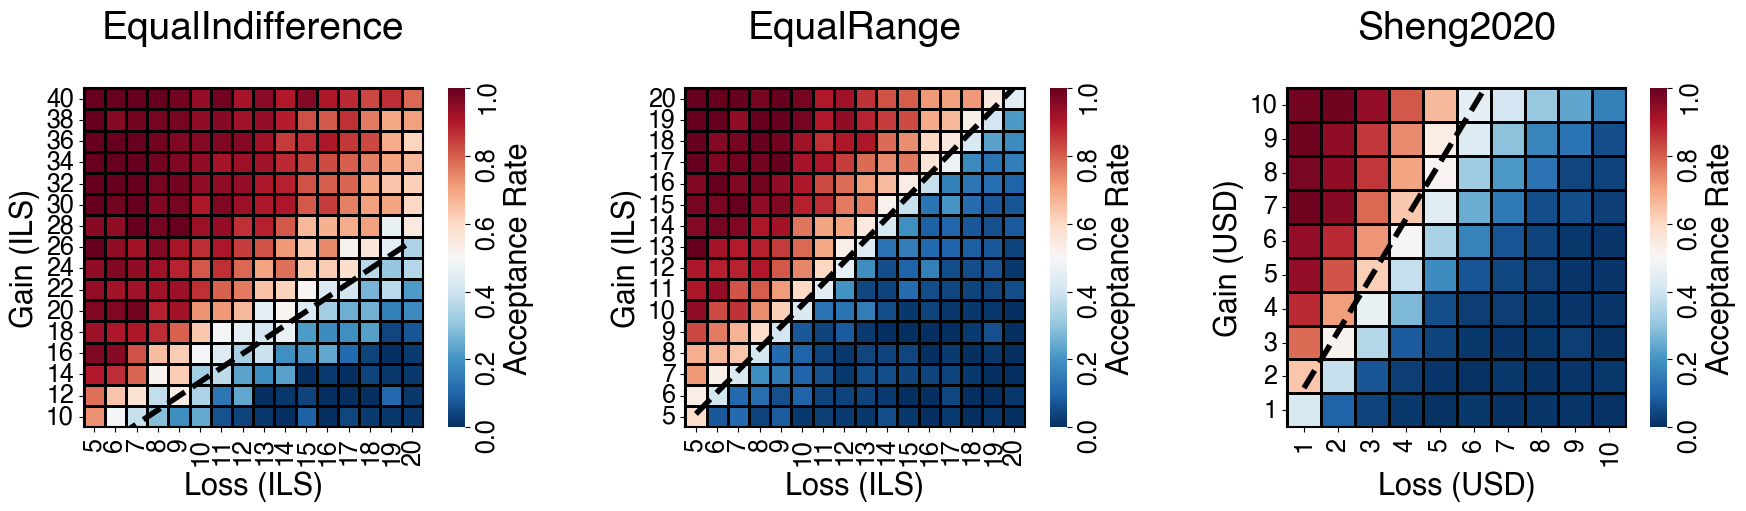

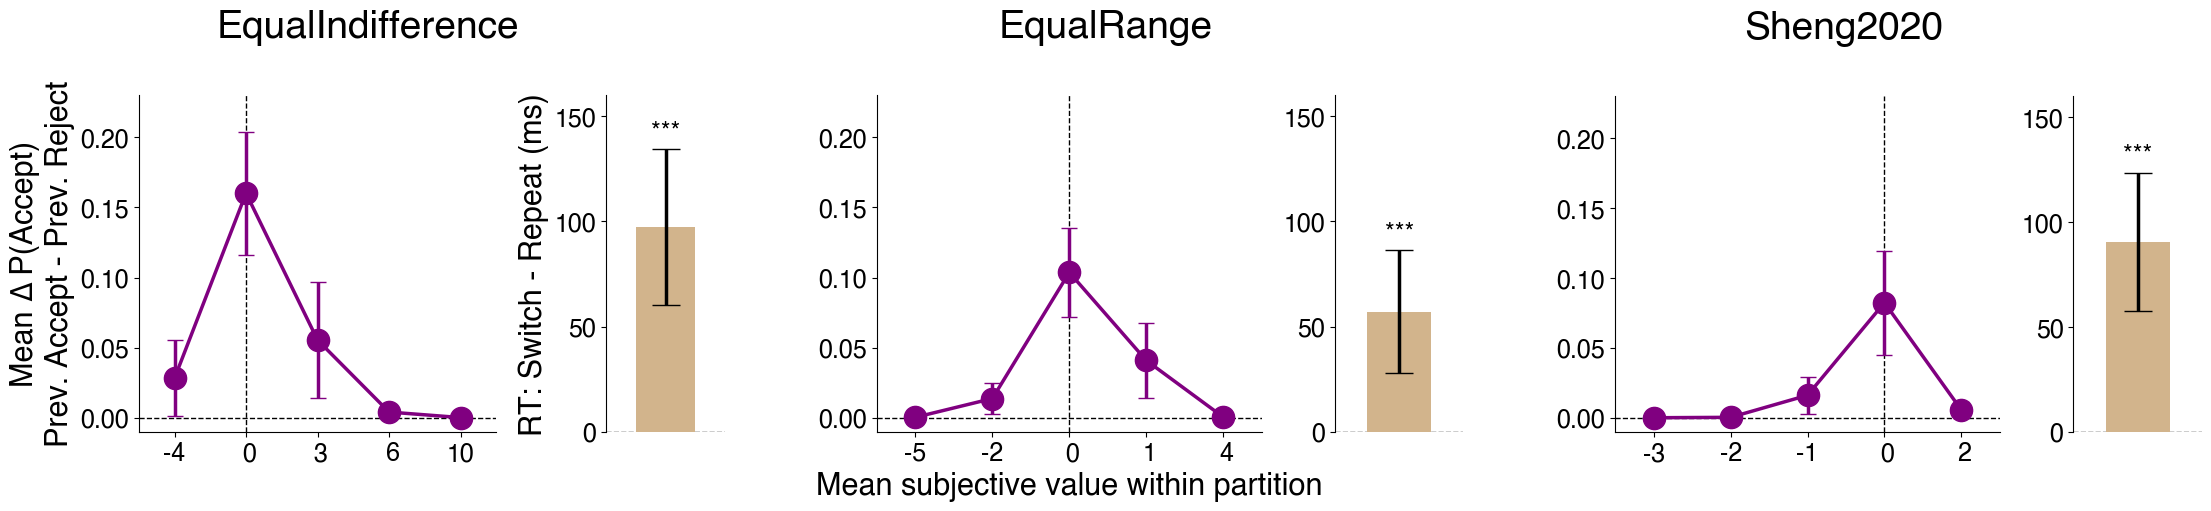

In [32]:
# --- Row 1: acceptance heatmaps ---
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), layout="constrained")
set_dataset_titles(axes)
draw_acceptance_row(axes)
fig.savefig("saved/figure2_v2_acceptance.svg", dpi=300, bbox_inches="tight")
plt.show()

# --- Row 2: choice-history effect by SV partition + switch RT bar, one block per dataset ---
fig = plt.figure(figsize=(22, 5), layout="constrained")
subfigs = fig.subfigures(nrows=1, ncols=len(DATASETS))
draw_historyeffect_row(subfigs)
fig.savefig("saved/figure2_v2_historyeffect.svg", dpi=300, bbox_inches="tight")
plt.show()